This is a simple code snippet that allow hand drawing to trim off unwanted regions in your original high velocity mask

- **Step 1:** install ipympl. You can run command "mamba install -c conda-forge ipympl" on your terminal with the environment activated, or running !pip install ipympl in your jupyter notebook. The first approach is recommended to avoid potential environmental conflict

- **Step 2:** get your original highvel_mask from velocity magnitude, as in the T1 notebook

- **Step 3:** copy paste the following code to your jupyter notebook, and then run it. You will see something similar to the image below. There are three operations I used the most:

Click the buttons at top left to use the tool for moving and zoom-in.

While no tool is selected, you can click and drag on the figure to create a box (sometimes the box is invisible). The mask inside the box will be set to zero.

If you have made a mistake, just rerun the entire cell, and the figure will be refreshed to your original high vel mask.

- **Step 4:** The new mask is saved in a variable called 'highvel_mask_new'. Set 'highvel_mask = highvel_mask_new' once you are satisfied with the new mask. At the end, you can run "%matplotlib inline" in a grid cell to toggle off the interactive plotting mode.

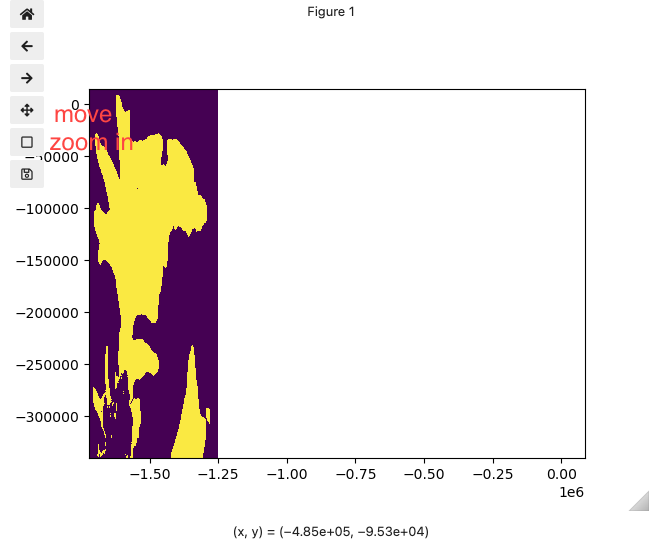

In [ ]:
%matplotlib widget
from matplotlib.widgets import RectangleSelector

highvel_mask_new = highvel_mask.copy()
fig, ax = plt.subplots()
ax.pcolormesh(xx, yy, highvel_mask_new)
highvel_mask_list = []

def onselect(eclick, erelease):
    x1, y1 = eclick.xdata, eclick.ydata
    x2, y2 = erelease.xdata, erelease.ydata
    
    xmin, xmax = min(x1, x2), max(x1, x2)
    ymin, ymax = min(y1, y2), max(y1, y2)
    
    mask_condition = (xx > xmin) & (xx < xmax) & (yy > ymin) & (yy < ymax)
    indexes = np.where(mask_condition)
    
    if len(indexes[0]) > 0 and len(indexes[1]) > 0:
        row_min, row_max = np.min(indexes[0]), np.max(indexes[0])
        col_min, col_max = np.min(indexes[1]), np.max(indexes[1])
        
        highvel_mask_new[row_min:row_max+1, col_min:col_max+1] = 0
        highvel_mask_list.append(highvel_mask_new)
        
        ax.clear()
        ax.pcolormesh(xx, yy, highvel_mask_new)
        fig.canvas.draw_idle()

selector = RectangleSelector(ax, onselect, interactive=True, 
                             props=dict(facecolor='red', edgecolor='black', alpha=0.2, fill=True))

plt.show()

In [ ]:
%matplotlib inline